<a href="https://colab.research.google.com/github/sanjil18/CNN-project/blob/main/CNN_project.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [19]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [20]:
import os
import time
import shutil
import torch
import torch.nn as nn
import torch.optim as optim
from sklearn.model_selection import train_test_split
from torchvision import datasets, transforms
from torch.utils.data import DataLoader

project_path = '/content/drive/MyDrive/CNN-project'
zip_path = f'{project_path}/intel-image-classification.zip'
data_dir = '/content/intel_data'
train_dir = f'{data_dir}/seg_train/seg_train'
val_dir = f'{data_dir}/seg_val'
test_dir = f'{data_dir}/seg_test/seg_test'

os.makedirs(project_path, exist_ok=True)

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('Device:', device)

Device: cuda


In [21]:
if os.path.exists(data_dir):
    print('Dataset ஏற்கனவே local-ல இருக்கு')
elif os.path.exists(zip_path):
    !unzip -q "{zip_path}" -d "{data_dir}"
    print('Dataset local-ல extract ஆயிடுச்சு')
else:
    print('Zip file Drive-ல இல்ல, Kaggle-ல இருந்து download பண்ணணும்')

Dataset local-ல extract ஆயிடுச்சு


In [22]:
already_split = os.path.exists(val_dir) and len(os.listdir(val_dir)) > 0

if already_split:
    print('Split ஏற்கனவே முடிஞ்சிருக்கு, skip பண்றோம்')
else:
    os.makedirs(val_dir, exist_ok=True)
    for cls in sorted(os.listdir(train_dir)):
        cls_path = os.path.join(train_dir, cls)
        images = sorted(os.listdir(cls_path))
        _, val_images = train_test_split(images, test_size=0.15, random_state=42)

        val_cls_dir = os.path.join(val_dir, cls)
        os.makedirs(val_cls_dir, exist_ok=True)

        for img_name in val_images:
            shutil.move(os.path.join(cls_path, img_name),
                        os.path.join(val_cls_dir, img_name))
        print(f'{cls}: moved {len(val_images)} images to val')

buildings: moved 329 images to val
forest: moved 341 images to val
glacier: moved 361 images to val
mountain: moved 377 images to val
sea: moved 342 images to val
street: moved 358 images to val


In [23]:
for name, path in [('train', train_dir), ('val', val_dir), ('test', test_dir)]:
    print(name)
    total = 0
    for cls in sorted(os.listdir(path)):
        n = len(os.listdir(os.path.join(path, cls)))
        total += n
        print('  ', cls, n)
    print('  total:', total)

train
   buildings 1862
   forest 1930
   glacier 2043
   mountain 2135
   sea 1932
   street 2024
  total: 11926
val
   buildings 329
   forest 341
   glacier 361
   mountain 377
   sea 342
   street 358
  total: 2108
test
   buildings 437
   forest 474
   glacier 553
   mountain 525
   sea 510
   street 501
  total: 3000


In [24]:
transform = transforms.Compose([
    transforms.Resize((150, 150)),
    transforms.ToTensor(),
    transforms.Normalize((0.5, 0.5, 0.5), (0.5, 0.5, 0.5)),
])

train_ds = datasets.ImageFolder(train_dir, transform=transform)
val_ds   = datasets.ImageFolder(val_dir, transform=transform)
test_ds  = datasets.ImageFolder(test_dir, transform=transform)

train_loader = DataLoader(train_ds, batch_size=32, shuffle=True,  num_workers=2)
val_loader   = DataLoader(val_ds,   batch_size=32, shuffle=False, num_workers=2)
test_loader  = DataLoader(test_ds,  batch_size=32, shuffle=False, num_workers=2)

print(train_ds.transform)
print(train_ds.class_to_idx)
print(len(train_ds), len(val_ds), len(test_ds))

Compose(
    Resize(size=(150, 150), interpolation=bilinear, max_size=None, antialias=True)
    ToTensor()
    Normalize(mean=(0.5, 0.5, 0.5), std=(0.5, 0.5, 0.5))
)
{'buildings': 0, 'forest': 1, 'glacier': 2, 'mountain': 3, 'sea': 4, 'street': 5}
11926 2108 3000


In [25]:
bad = 0
for images, labels in train_loader:
    if images.shape[1:] != (3, 150, 150):
        bad += 1
print('Bad batches:', bad)

Bad batches: 0


In [26]:
class SimpleCNN(nn.Module):
    def __init__(self, num_classes=6):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(3, 32, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.Conv2d(64, 128, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),
        )
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(128 * 18 * 18, 256),
            nn.ReLU(),
            nn.Dropout(0.5),
            nn.Linear(256, num_classes),
        )

    def forward(self, x):
        x = self.features(x)
        x = self.classifier(x)
        return x

model = SimpleCNN().to(device)
optimizer = optim.Adam(model.parameters(), lr=0.001)
criterion = nn.CrossEntropyLoss()

print('Total params:', sum(p.numel() for p in model.parameters()))

Total params: 10711878


In [27]:
def run_epoch(loader, train=True):
    model.train() if train else model.eval()
    total_loss, correct, total = 0.0, 0, 0

    with torch.set_grad_enabled(train):
        for images, labels in loader:
            images, labels = images.to(device), labels.to(device)

            outputs = model(images)
            loss = criterion(outputs, labels)

            if train:
                optimizer.zero_grad()
                loss.backward()
                optimizer.step()

            total_loss += loss.item() * images.size(0)
            correct += (outputs.argmax(1) == labels).sum().item()
            total += labels.size(0)

    return total_loss / total, correct / total

In [28]:
EPOCHS = 10
history = {'train_loss': [], 'val_loss': [], 'train_acc': [], 'val_acc': []}
best_val_acc = 0.0
save_path = f'{project_path}/best_scratch_cnn.pth'

for epoch in range(EPOCHS):
    start = time.time()
    tr_loss, tr_acc = run_epoch(train_loader, train=True)
    va_loss, va_acc = run_epoch(val_loader, train=False)

    history['train_loss'].append(tr_loss)
    history['val_loss'].append(va_loss)
    history['train_acc'].append(tr_acc)
    history['val_acc'].append(va_acc)

    if va_acc > best_val_acc:
        best_val_acc = va_acc
        torch.save(model.state_dict(), save_path)
        saved = '  ← best, saved'
    else:
        saved = ''

    print(f'Epoch {epoch+1}/{EPOCHS} | '
          f'train loss {tr_loss:.3f} acc {tr_acc:.3f} | '
          f'val loss {va_loss:.3f} acc {va_acc:.3f} | '
          f'{time.time()-start:.0f}s{saved}')

Epoch 1/10 | train loss 0.968 acc 0.624 | val loss 0.689 acc 0.742 | 19s  ← best, saved
Epoch 2/10 | train loss 0.648 acc 0.765 | val loss 0.593 acc 0.775 | 18s  ← best, saved
Epoch 3/10 | train loss 0.517 acc 0.813 | val loss 0.522 acc 0.801 | 19s  ← best, saved
Epoch 4/10 | train loss 0.416 acc 0.848 | val loss 0.561 acc 0.803 | 19s  ← best, saved
Epoch 5/10 | train loss 0.336 acc 0.882 | val loss 0.577 acc 0.818 | 19s  ← best, saved
Epoch 6/10 | train loss 0.261 acc 0.910 | val loss 0.550 acc 0.823 | 19s  ← best, saved
Epoch 7/10 | train loss 0.199 acc 0.926 | val loss 0.623 acc 0.828 | 18s  ← best, saved
Epoch 8/10 | train loss 0.144 acc 0.949 | val loss 0.680 acc 0.817 | 20s
Epoch 9/10 | train loss 0.120 acc 0.956 | val loss 0.873 acc 0.803 | 18s
Epoch 10/10 | train loss 0.124 acc 0.957 | val loss 0.775 acc 0.819 | 18s


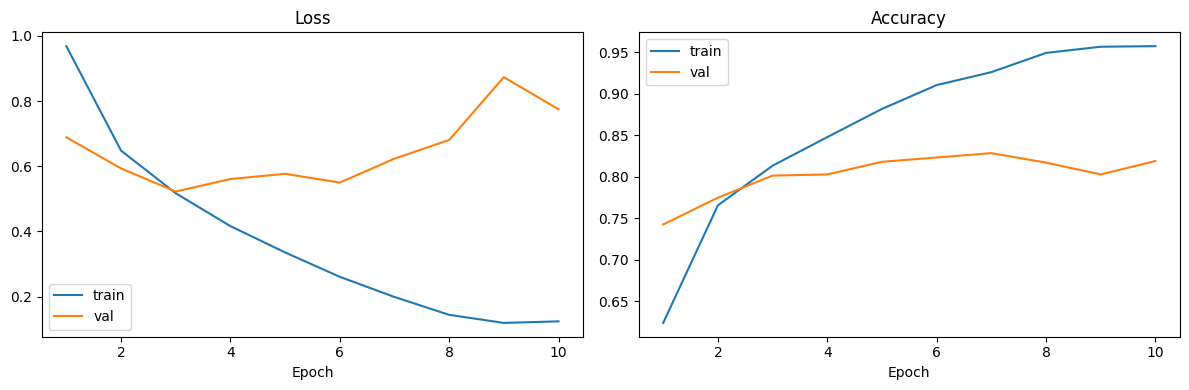

In [29]:
import json
import matplotlib.pyplot as plt

with open(f'{project_path}/history_scratch.json', 'w') as f:
    json.dump(history, f)

epochs = range(1, len(history['train_loss']) + 1)
fig, ax = plt.subplots(1, 2, figsize=(12, 4))

ax[0].plot(epochs, history['train_loss'], label='train')
ax[0].plot(epochs, history['val_loss'], label='val')
ax[0].set_title('Loss')
ax[0].set_xlabel('Epoch')
ax[0].legend()

ax[1].plot(epochs, history['train_acc'], label='train')
ax[1].plot(epochs, history['val_acc'], label='val')
ax[1].set_title('Accuracy')
ax[1].set_xlabel('Epoch')
ax[1].legend()

plt.tight_layout()
plt.savefig(f'{project_path}/scratch_curves.png', dpi=150)
plt.show()

In [30]:
model.load_state_dict(torch.load(save_path, map_location=device))
test_loss, test_acc = run_epoch(test_loader, train=False)
print(f'Test loss {test_loss:.3f} | Test acc {test_acc:.3f}')

Test loss 0.573 | Test acc 0.838
